# Práctica 1. Evaluación de clasificadores clásicos sobre MNIST

**Asignatura:** Redes Neuronales y Aprendizaje Profundo  
**Institución:** Instituto Politécnico Nacional (UPIIT)  
**Objetivo:** Analizar el conjunto de datos MNIST y comparar clasificadores clásicos mediante un protocolo experimental riguroso (particiones, métricas y pruebas estadísticas).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

NumPy: 2.5.4
Pandas: 3.0.6


## 1. Actividad 1. Análisis Exploratorio de Datos (EDA)

### 1a. Estructura básica y balance de clases
*Conteo de ejemplos, dimensiones, tipos de datos, rango de valores, valores faltantes y análisis del balance de clases entre entrenamiento y prueba.*

In [2]:
from sklearn.datasets import fetch_openml

mnist = fetch_openml(
    "mnist_784",
    version=1,
    as_frame=False,
    parser="auto"
)

X = mnist.data #dartos de entrada (px)
y = mnist.target.astype(int) #etiquetas (No. img)

print("Dataset MNIST cargado correctamente")

Dataset MNIST cargado correctamente


In [3]:
print("Dimensiones de X", X.shape) #img x carct
print("Dimensiones de Y", y.shape) #imgs

print("\nNumero de imagenes:", X.shape[0])
print("Caracteristicas por imagen", X.shape[1])

Dimensiones de X (70000, 784)
Dimensiones de Y (70000,)

Numero de imagenes: 70000
Caracteristicas por imagen 784


Clases encontradas: [0 1 2 3 4 5 6 7 8 9]
NUmero de clases: 10

Cantidad de imagenes por clase:
Digito0: 6903 imagenes
Digito1: 7877 imagenes
Digito2: 6990 imagenes
Digito3: 7141 imagenes
Digito4: 6824 imagenes
Digito5: 6313 imagenes
Digito6: 6876 imagenes
Digito7: 7293 imagenes
Digito8: 6825 imagenes
Digito9: 6958 imagenes


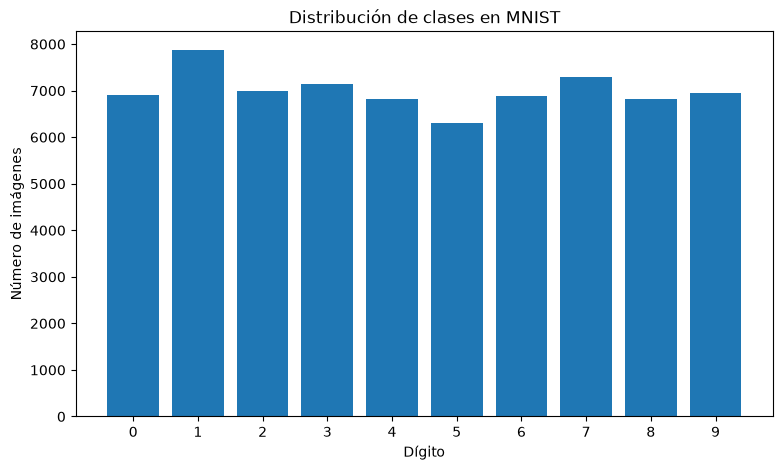

In [4]:
clases, cantidades = np.unique(y, return_counts=True) #valores en y y repeticion

print("Clases encontradas:", clases)
print("NUmero de clases:", len(clases))

print("\nCantidad de imagenes por clase:")
for clase, cantidad in zip(clases, cantidades): #clase y cantidad
    print(f"Digito{clase}: {cantidad} imagenes")


plt.figure(figsize=(9, 5))

plt.bar(clases, cantidades)

plt.title("Distribución de clases en MNIST")
plt.xlabel("Dígito")
plt.ylabel("Número de imágenes")
plt.xticks(clases)

plt.show()

**Interpretación:** Como se puede observar nuestra dataset si contiene las 10 clases del 0 al 9. \n Se puede observar que la cantidad de imagenes no es la misma, sin embargo no existe un abismo de diferencia por lo tanto no es muy grande el desbalance

In [5]:
print("Intensidad minima:", np.min(X))
print("Intensidad maxima:", np.max(X))
print("Promedio:", np.mean(X))
print("Mediana:", np.median(X))
print("Desviacion estandar:", np.std(X))
print("Suma de los valores faltantes: ", np.isnan(X).sum())
print("Tipo de dato: ", type(X))
print(X.dtype, y.dtype)


Intensidad minima: 0
Intensidad maxima: 255
Promedio: 33.385964741253645
Mediana: 0.0
Desviacion estandar: 78.65437362689416
Suma de los valores faltantes:  0
Tipo de dato:  <class 'numpy.ndarray'>
int64 int64


### Graficamos el desbalance de las clases

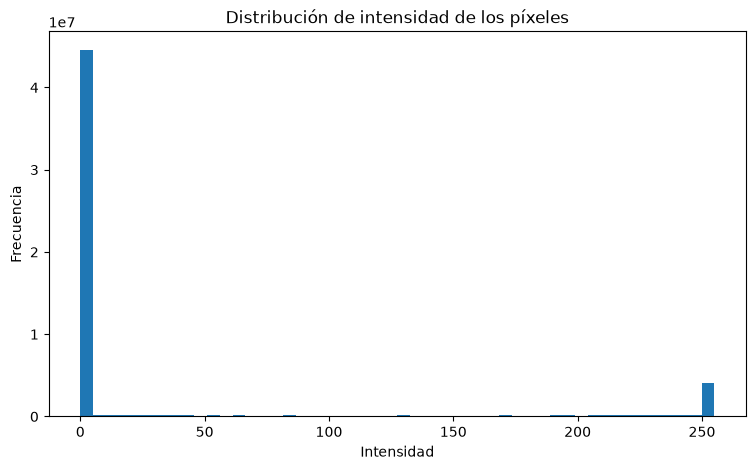

In [6]:
plt.figure(figsize=(9, 5))

plt.hist(X.ravel(), bins=50)

plt.title("Distribución de intensidad de los píxeles")
plt.xlabel("Intensidad")
plt.ylabel("Frecuencia")

plt.show()

**Interpretación:** Como sabemos las intensidades van de 0 a 255, podemos observar en la gráfica que la frecuencia que mas se repite es el 0, por lo tanto la mediana es 0 y promedio aproximado 33.39, esto hace sentido ya que gran parte de los pixeles representa el fondo.

### 1b. Visualización de ejemplos y características generales
*Muestreo aleatorio de dígitos, imágenes promedio, desviación estándar, mapa de calor de varianza de píxeles y distribución de la intensidad.*

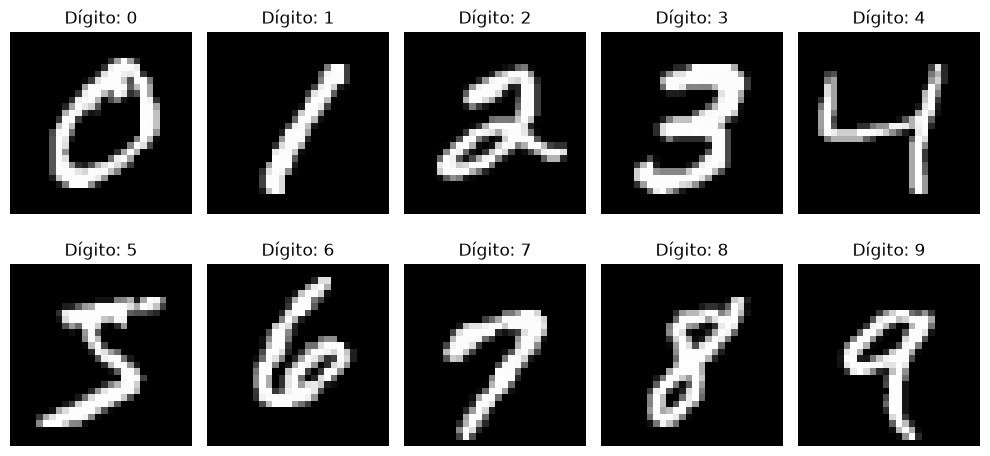

In [7]:
fig, axes = plt.subplots(2, 5, figsize=(10, 5)) #fig en 10 para mostrar 10 img

for digito, ax in enumerate(axes.flat): #0 a 9
    indice = np.where(y == digito)[0][0] #dig en y y toma img
    imagen = X[indice].reshape(28, 28) #toma img de 784 y la regresa a 28x28

    ax.imshow(imagen, cmap="gray") #Img a escala de grises
    ax.set_title(f"Dígito: {digito}")
    ax.axis("off")

plt.tight_layout()
plt.show()

mapa de calor con la varianza de cada pixel


Píxeles con varianza cero en todas las imágenes: 65


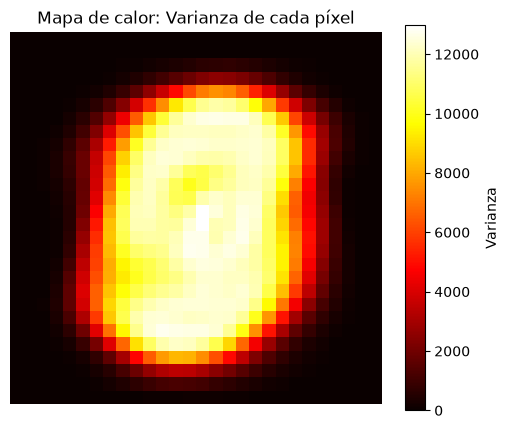

In [8]:
varianzas = np.var(X, axis= 0)
pixeles_var = np.sum(varianzas == 0)

print(f"Píxeles con varianza cero en todas las imágenes: {pixeles_var}")

# Mapa de calor de la varianza
plt.figure(figsize=(6, 5))
plt.imshow(varianzas.reshape(28, 28), cmap='hot')
plt.title("Mapa de calor: Varianza de cada píxel")
plt.colorbar(label='Varianza')
plt.axis("off")
plt.show()



Como podemos observar, hay píxeles con varianza igual a cero (que siempre están en negro). Esto corresponde a los bordes de la imagen de $28 \times 28$. Para los modelos, esto implica que esos píxeles no aportan ninguna información útil para discriminar entre un dígito y otro, por lo que podrían eliminarse para reducir la dimensionalidad y acelerar el tiempo de entrenamiento sin perder precisión.

#### Diagrama de intensisdad media 


/tmp/ipykernel_28412/206009367.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=y, y=intensidad_med, palette="Set3")


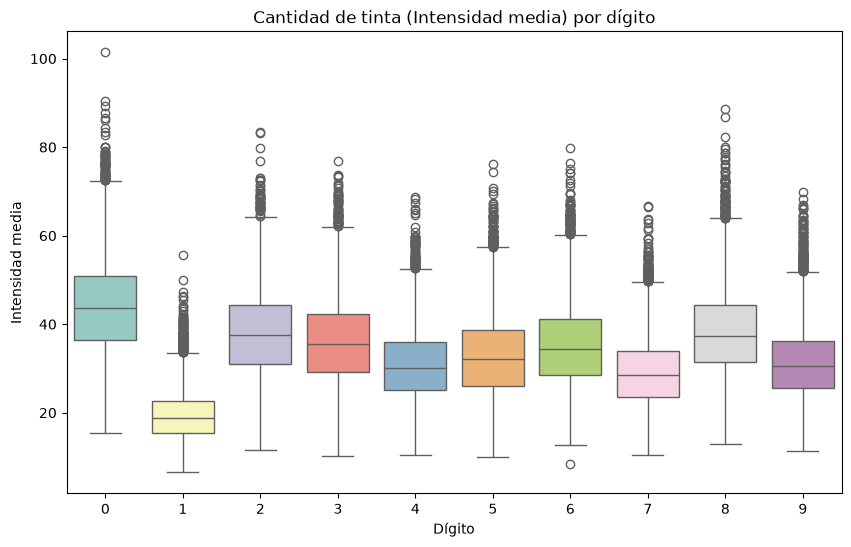

In [9]:
import seaborn as sns
intensidad_med = np.mean(X, axis=1)

plt.figure(figsize=(10, 6))
sns.boxplot(x=y, y=intensidad_med, palette="Set3")
plt.title("Cantidad de tinta (Intensidad media) por dígito")
plt.xlabel("Dígito")
plt.ylabel("Intensidad media")
plt.show()


Observando el diagrama de caja, se confirma claramente que el dígito 1 utiliza menos tinta (intensidad media más baja) en comparación con el dígito 8, que tiene una de las medianas más altas debido a que requiere más trazos para dibujarse.

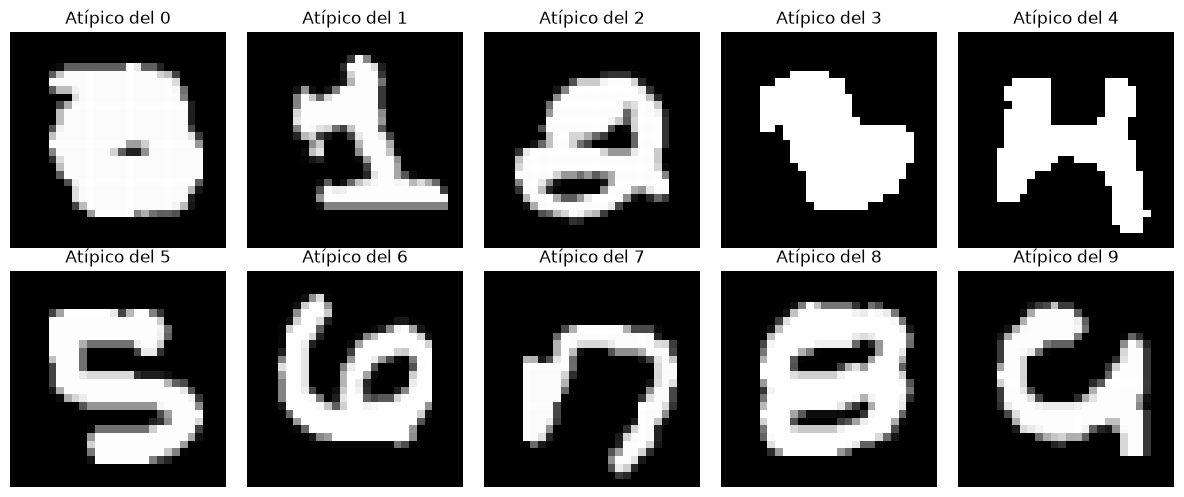

In [10]:
fig, axes = plt.subplots(2, 5, figsize = (12, 5))

for digito, ax in enumerate(axes.flat):
    #buscamos por clase
    x_clase = X[y == digito]

    #calculamos el primedio
    img_promedio = np.mean(x_clase, axis=0)

    #Calculamos la distacia euclidiana
    distancia = np.linalg.norm(x_clase - img_promedio, axis=1)

    #buscamos los indices q son meyores
    indice_atipico = np.argmax(distancia)
    img_atipica = x_clase[indice_atipico].reshape(28, 28)
    ax.imshow(img_atipica, cmap="gray")
    ax.set_title(f"Atípico del {digito}")
    ax.axis("off")

plt.tight_layout()
plt.show()

Estas imágenes representan los casos más alejados del promedio de su clase. Suelen ser dígitos escritos con trazos extremadamente gruesos, sesgados, incompletos o con un estilo de escritura muy inusual, lo cual representa los casos más difíciles que los clasificadores tendrán que afrontar.

### 1c. Similitud entre clases e hipótesis explícita
*Matriz de distancia euclidiana entre imágenes promedio por clase para formular hipótesis sobre las parejas de dígitos con mayor riesgo de confusión.*

In [11]:
estadisticas_clases = []

for digito in clases:
    imagenes_clase = X[y == digito] #imgs que pertenecen a un digito

    promedio = np.mean(imagenes_clase)
    desviacion = np.std(imagenes_clase)

    estadisticas_clases.append([digito, promedio, desviacion]) #guardar y hacer tabla

tabla_estadisticas = pd.DataFrame(
    estadisticas_clases,
    columns=["Dígito", "Promedio", "Desviación estándar"]
)

tabla_estadisticas


,Dígito,Promedio,Desviación estándar
0,0,44.177405,88.643286
1,1,19.406802,62.347559
2,2,38.034208,83.171552
3,3,36.154209,81.154922
4,4,30.996000,75.925956
5,5,32.950159,77.565749
6,6,35.234865,80.541918
7,7,29.217987,74.404598
8,8,38.397901,83.059082
9,9,31.359408,76.280703


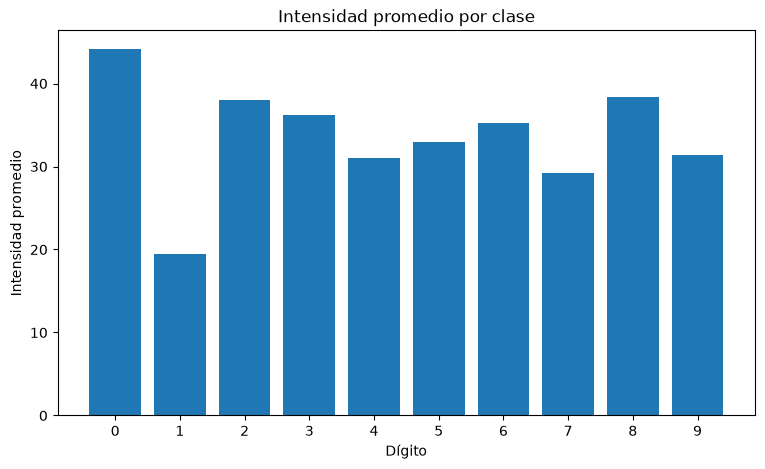

In [12]:
plt.figure(figsize=(9, 5))

plt.bar(
    tabla_estadisticas["Dígito"],
    tabla_estadisticas["Promedio"]
)

plt.title("Intensidad promedio por clase")
plt.xlabel("Dígito")
plt.ylabel("Intensidad promedio")
plt.xticks(clases)

plt.show()

**Interpretación:** La intensidad promedio presenta diferencias entre las clases. El dígito 0 presenta el promedio más alto, con aproximadamente 44.18, mientras que el dígito 1 presenta el menor, con aproximadamente 19.41.\nEstas diferencias pueden estar relacionadas con la cantidad de píxeles que ocupan los trazos de cada dígito. Sin embargo, los valores promedio no describen por completo la forma de las imágenes y existe variabilidad dentro de cada clase.

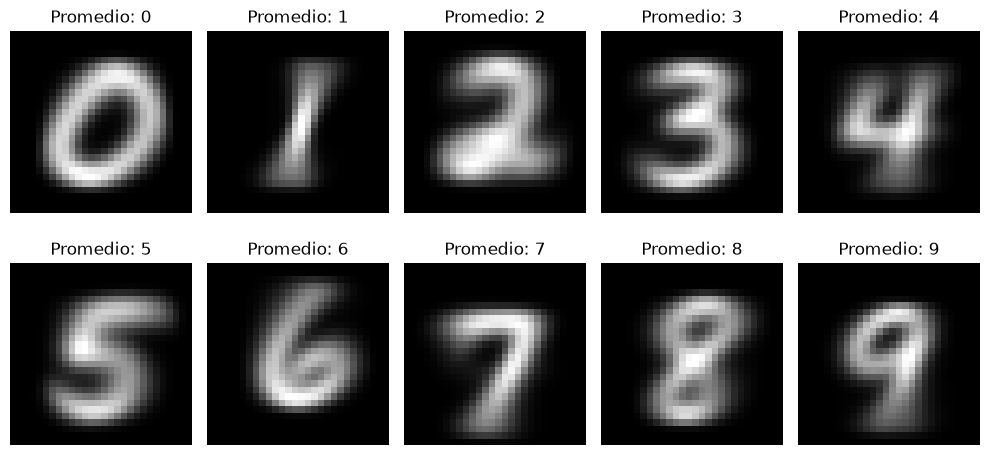

In [13]:
fig, axes = plt.subplots(2,5, figsize=(10,5))

for digito, ax in enumerate(axes.flat):
    imagenes_clase = X[y == digito]

    imagen_promedio = np.mean(imagenes_clase, axis=0) #promedio pixel por pixel
    imagen_promedio = imagen_promedio.reshape(28, 28)


    ax.imshow(imagen_promedio, cmap="gray")
    ax.set_title(f"Promedio: {digito}")
    ax.axis("off")

plt.tight_layout()
plt.show()

#### Matriz 10x10 de las distancias


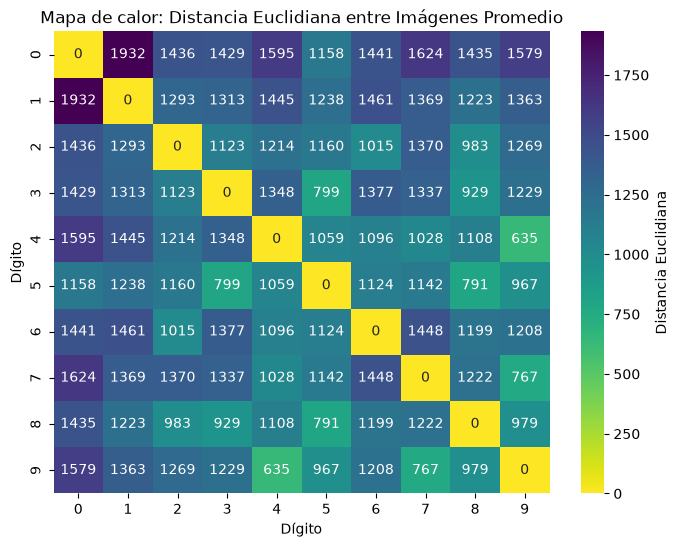

In [14]:
promedios = np.array([np.mean(X[y == i], axis=0) for i in range(10)])

distancias = np.zeros((10,10))
for i in range(10):
    for j in range(10):
        distancias[i, j] = np.linalg.norm(promedios[i] - promedios[j])

plt.figure(figsize=(8, 6))
sns.heatmap(distancias, annot=True, fmt=".0f", cmap="viridis_r", 
            cbar_kws={'label': 'Distancia Euclidiana'})
plt.title("Mapa de calor: Distancia Euclidiana entre Imágenes Promedio")
plt.xlabel("Dígito")
plt.ylabel("Dígito")
plt.show()

Observando el mapa de calor, los valores más bajos (excluyendo la diagonal principal que es 0) indican una menor distancia euclidiana y, por lo tanto, una mayor similitud visual entre los promedios de esas clases

- Pareja	Distancia
- 4 – 9	| 635
- 7 – 9	| 767
- 5 – 8	| 791
- 3 – 5	| 799
- 3 – 8	| 929 



## 2. Actividad 2. Protocolo Experimental y Particiones

### 2a. Comparación de esquemas de partición
*Implementación y evaluación de esquemas: Hold-out simple estratificado, Hold-out sin estratificar, K-Fold estratificado y K-Fold repetido ($5 \times 2$).*

##### Hold-out simple

In [15]:
X_train, y_train = X[:60000], y[:60000]
X_test, y_test = X[60000:], y[60000:]

print("Entrenamiento:")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\nPrueba:")
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

clases_train, cantidades_train = np.unique(y_train, return_counts=True) #ej de cada dig
clases_test, cantidades_test = np.unique(y_test, return_counts=True)

print("\nClase | Train | Test")
print("--------------------")

for clase, train, test in zip(clases_train, cantidades_train, cantidades_test): #juntamos los 3 datos
    print(f"  {clase}   | {train:5d} | {test:4d}")

Entrenamiento:
X_train: (60000, 784)
y_train: (60000,)

Prueba:
X_test: (10000, 784)
y_test: (10000,)

Clase | Train | Test
--------------------
  0   |  5923 |  980
  1   |  6742 | 1135
  2   |  5958 | 1032
  3   |  6131 | 1010
  4   |  5842 |  982
  5   |  5421 |  892
  6   |  5918 |  958
  7   |  6265 | 1028
  8   |  5851 |  974
  9   |  5949 | 1009


##### Hold-out con estrateficacion 

In [16]:
from sklearn.model_selection import train_test_split
# Hold-out estratificado 
X_train_holdout, X_valid_holdout, y_train_holdout, y_valid_holdout = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    stratify=y_train,
    random_state=42
)

print("Entrenamiento para hold-out:", X_train_holdout.shape, y_train_holdout.shape)
print("Validación para hold-out:", X_valid_holdout.shape, y_valid_holdout.shape)



Entrenamiento para hold-out: (48000, 784) (48000,)
Validación para hold-out: (12000, 784) (12000,)


#### 2a. Comparación de esquemas de partición

In [17]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score, StratifiedKFold, RepeatedStratifiedKFold

# Instanciamos un clasificador rápido (Regresión Logística)
clf_base = LogisticRegression(max_iter=100, solver='lbfgs', n_jobs=-1)

# 1. K-Fold Estratificado (K=5)
# Se justifica K=5 porque es un estándar
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores_skf = cross_val_score(clf_base, X_train, y_train, cv=skf, scoring='accuracy', n_jobs=-1)

print("K-Fold Estratificado (K=5):")
print(f"Puntajes por pliegue: {scores_skf}")
print(f"Media: {scores_skf.mean():.4f} | Desviación Estándar: {scores_skf.std():.4f}\n")

# 2. K-Fold Repetido (5 repeticiones de 2 pliegues - 5x2)
rskf = RepeatedStratifiedKFold(n_splits=2, n_repeats=5, random_state=42)
scores_rskf = cross_val_score(clf_base, X_train, y_train, cv=rskf, scoring='accuracy', n_jobs=-1)

print("K-Fold Repetido (5x2):")
print(f"Media: {scores_rskf.mean():.4f} | Desviación Estándar: {scores_rskf.std():.4f}")

/home/kevincho/Documentos/6to-semestre/RedesNeuronales/MNIST/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/kevincho/Documentos/6to-semestre/RedesNeuronales/MNIST/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/kevincho/Documentos/6to-semestre/RedesNeuronales/MNIST/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/kevincho/Documentos/6to-semestre/RedesNeuronales/MNIST/

K-Fold Estratificado (K=5):
Puntajes por pliegue: [0.91808333 0.92266667 0.91775    0.91666667 0.91866667]
Media: 0.9188 | Desviación Estándar: 0.0021



/home/kevincho/Documentos/6to-semestre/RedesNeuronales/MNIST/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/kevincho/Documentos/6to-semestre/RedesNeuronales/MNIST/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/kevincho/Documentos/6to-semestre/RedesNeuronales/MNIST/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/kevincho/Documentos/6to-semestre/RedesNeuronales/MNIST/

K-Fold Repetido (5x2):
Media: 0.9126 | Desviación Estándar: 0.0020


In [18]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score, StratifiedKFold, RepeatedStratifiedKFold

# Instanciamos un clasificador rápido (Regresión Logística)
clf_base = LogisticRegression(max_iter=100, solver='lbfgs', n_jobs=-1)

# 1. K-Fold Estratificado (K=5)
# Se justifica K=5 porque es un estándar
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores_skf = cross_val_score(clf_base, X_train_holdout, y_train_holdout, cv=skf, scoring='accuracy', n_jobs=-1)

print("K-Fold Estratificado con hold out  (K=5):")
print(f"Puntajes por pliegue: {scores_skf}")
print(f"Media: {scores_skf.mean():.4f} | Desviación Estándar: {scores_skf.std():.4f}\n")

# 2. K-Fold Repetido (5 repeticiones de 2 pliegues - 5x2)
rskf = RepeatedStratifiedKFold(n_splits=2, n_repeats=5, random_state=42)
scores_rskf = cross_val_score(clf_base, X_train_holdout, y_train_holdout, cv=rskf, scoring='accuracy', n_jobs=-1)

print("K-Fold Repetido con hold out estatificado(5x2):")
print(f"Media: {scores_rskf.mean():.4f} | Desviación Estándar: {scores_rskf.std():.4f}")

/home/kevincho/Documentos/6to-semestre/RedesNeuronales/MNIST/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/kevincho/Documentos/6to-semestre/RedesNeuronales/MNIST/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/kevincho/Documentos/6to-semestre/RedesNeuronales/MNIST/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/kevincho/Documentos/6to-semestre/RedesNeuronales/MNIST/

K-Fold Estratificado con hold out  (K=5):
Puntajes por pliegue: [0.91739583 0.91333333 0.91604167 0.91260417 0.91729167]
Media: 0.9153 | Desviación Estándar: 0.0020



/home/kevincho/Documentos/6to-semestre/RedesNeuronales/MNIST/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/kevincho/Documentos/6to-semestre/RedesNeuronales/MNIST/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/kevincho/Documentos/6to-semestre/RedesNeuronales/MNIST/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/kevincho/Documentos/6to-semestre/RedesNeuronales/MNIST/

K-Fold Repetido con hold out estatificado(5x2):
Media: 0.9073 | Desviación Estándar: 0.0014




### 2c. Fuga de información, línea base y curva de aprendizaje
*Diseño de Pipelines para evitar la fuga de información, clasificación de línea base (`DummyClassifier`) y análisis de curvas de aprendizaje.*

Línea base (most_frequent) - Accuracy: 0.1135
Línea base (stratified) - Accuracy: 0.1001



/home/kevincho/Documentos/6to-semestre/RedesNeuronales/MNIST/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/kevincho/Documentos/6to-semestre/RedesNeuronales/MNIST/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/kevincho/Documentos/6to-semestre/RedesNeuronales/MNIST/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/kevincho/Documentos/6to-semestre/RedesNeuronales/MNIST/

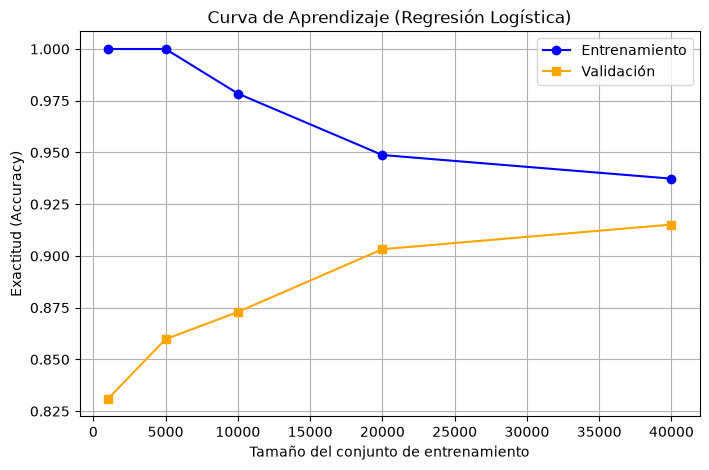

In [19]:
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import learning_curve




# Modelos de Línea Base
dummy_freq = DummyClassifier(strategy='most_frequent')
dummy_freq.fit(X_train, y_train)
acc_freq = dummy_freq.score(X_test, y_test)

dummy_strat = DummyClassifier(strategy='stratified', random_state=42)
dummy_strat.fit(X_train, y_train)
acc_strat = dummy_strat.score(X_test, y_test)

print(f"Línea base (most_frequent) - Accuracy: {acc_freq:.4f}")
print(f"Línea base (stratified) - Accuracy: {acc_strat:.4f}\n")

# Curva de Aprendizaje 
train_sizes = np.array([1000, 5000, 10000, 20000, 40000])
sizes, train_scores, val_scores = learning_curve(
    clf_base, X_train, y_train, 
    train_sizes=train_sizes, 
    cv=3, scoring='accuracy', n_jobs=-1
)

train_mean = np.mean(train_scores, axis=1)
val_mean = np.mean(val_scores, axis=1)

# Gráfica
plt.figure(figsize=(8, 5))
plt.plot(sizes, train_mean, label='Entrenamiento', marker='o', color='blue')
plt.plot(sizes, val_mean, label='Validación', marker='s', color='orange')
plt.title('Curva de Aprendizaje (Regresión Logística)')
plt.xlabel('Tamaño del conjunto de entrenamiento')
plt.ylabel('Exactitud (Accuracy)')
plt.legend()
plt.grid()
plt.show()

In [20]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

pipe = Pipeline([
    ("escalador", StandardScaler()),
    ("modelo", LogisticRegression(max_iter=1000))
])
cross_val_score(pipe, X_train, y_train, cv=5)

array([0.91441667, 0.90591667, 0.91008333, 0.90558333, 0.92125   ])

## 3. Actividad 3. Clasificadores Clásicos e Hiperparámetros

### 3a. Selección y búsqueda de hiperparámetros
*Entrenamiento y ajuste mediante `GridSearchCV` / `RandomizedSearchCV` con `StratifiedKFold` para al menos 5 familias de algoritmos (k-NN, Regresión Logística, SVM, Árboles, Random Forest, Naive Bayes, etc.).*


---

In [23]:
from sklearn.model_selection import train_test_split, RandomizedSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
import time

# 1. Crear un subconjunto estratificado de 10,000 ejemplos para agilizar la búsqueda
X_train_sub, _, y_train_sub, _ = train_test_split(
    X_train, y_train, train_size=10000, stratify=y_train, random_state=42
)

# 2. Definir K-Fold estratificado para la búsqueda
skf_search = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

# 3. Diccionario para guardar los mejores modelos encontrados
mejores_modelos = {}

# 4. Definir Pipelines y espacios de hiperparámetros
modelos = {
    "k-NN": {
        "pipe": Pipeline([('scaler', MinMaxScaler()), ('knn', KNeighborsClassifier(n_jobs=-1))]),
        "params": {'knn__n_neighbors': [3, 5, 7, 9], 'knn__weights': ['uniform', 'distance']}
    },
    "Regresión Logística": {
        "pipe": Pipeline([('scaler', MinMaxScaler()), ('lr', LogisticRegression(max_iter=1000, n_jobs=-1))]),
        "params": {'lr__C': np.logspace(-2, 2, 5)} # Escala logarítmica
    },
    "SVM (RBF)": {
        "pipe": Pipeline([('scaler', MinMaxScaler()), ('svm', SVC())]),
        "params": {'svm__C': np.logspace(-1, 1, 3), 'svm__gamma': ['scale', 'auto']} # Escala logarítmica
    },
    "Árbol de Decisión": {
        "pipe": Pipeline([('dt', DecisionTreeClassifier(random_state=42))]),
        "params": {'dt__max_depth': [10, 20, 30, None], 'dt__min_samples_split': [2, 5, 10]}
    },
    "Random Forest": {
        "pipe": Pipeline([('rf', RandomForestClassifier(random_state=42, n_jobs=-1))]),
        "params": {'rf__n_estimators': [50, 100], 'rf__max_depth': [10, 20, None]}
    }
}

### 3b. Curvas de validación y costo computacional
*Análisis de bajo/sobreajuste mediante curvas de validación y medición de tiempos de entrenamiento y predicción.*

In [24]:
# Búsqueda de hiperparámetros con RandomizedSearchCV
for nombre, config in modelos.items():
    print(f"Buscando mejores hiperparámetros para: {nombre}...")
    inicio = time.time()
    
    # n_iter=3 explora 3 combinaciones aleatorias para no demorar demasiado
    search = RandomizedSearchCV(
        config["pipe"], 
        param_distributions=config["params"], 
        n_iter=3, cv=skf_search, scoring='accuracy', 
        random_state=42, n_jobs=-1
    )
    
    search.fit(X_train_sub, y_train_sub)
    tiempo_busqueda = time.time() - inicio
    
    mejores_modelos[nombre] = search.best_estimator_
    
    print(f"  Mejores parámetros: {search.best_params_}")
    print(f"  Mejor exactitud en CV: {search.best_score_:.4f}")
    print(f"  Tiempo de búsqueda: {tiempo_busqueda:.2f} segundos\n")

Buscando mejores hiperparámetros para: k-NN...
  Mejores parámetros: {'knn__weights': 'distance', 'knn__n_neighbors': 3}
  Mejor exactitud en CV: 0.9441
  Tiempo de búsqueda: 4.50 segundos

Buscando mejores hiperparámetros para: Regresión Logística...


c:\Users\monts\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1457: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


  Mejores parámetros: {'lr__C': np.float64(0.1)}
  Mejor exactitud en CV: 0.9025
  Tiempo de búsqueda: 12.44 segundos

Buscando mejores hiperparámetros para: SVM (RBF)...
  Mejores parámetros: {'svm__gamma': 'auto', 'svm__C': np.float64(10.0)}
  Mejor exactitud en CV: 0.9317
  Tiempo de búsqueda: 125.67 segundos

Buscando mejores hiperparámetros para: Árbol de Decisión...
  Mejores parámetros: {'dt__min_samples_split': 2, 'dt__max_depth': 10}
  Mejor exactitud en CV: 0.7857
  Tiempo de búsqueda: 6.54 segundos

Buscando mejores hiperparámetros para: Random Forest...
  Mejores parámetros: {'rf__n_estimators': 100, 'rf__max_depth': None}
  Mejor exactitud en CV: 0.9406
  Tiempo de búsqueda: 5.91 segundos



##### medicion de tiempos 

In [25]:
import time

resultados_modelos= []

for nombre, modelo in mejores_modelos.items():
    #medimos el tiempo del entrenamiento 
    inicio_train = time.time()
    modelo.fit(X_train_sub, y_train_sub )
    tiempo_train = time.time() - inicio_train

    #mediomos el tiempo de prediccion 
    inicio_predic = time.time()
    predicc = modelo.predict(X_test[:2000])
    tiempo_test = time.time() - inicio_predic

    acc = np.mean(predicc == y_test[:2000])

    resultados_modelos.append({
        "modelos ": nombre,
        "Entrenamiento en segundos": tiempo_train,
        "Prediccion con 2mil en segundos" : tiempo_test,
        "Accurracy en test ": acc
    }) 
df_tiempos = pd.DataFrame(resultados_modelos)
display(df_tiempos)

c:\Users\monts\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1457: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


,modelos,Entrenamiento en segundos,Prediccion con 2mil en segundos,Accurracy en test
0,k-NN,0.198428,5.104675,0.9220
1,Regresión Logística,3.274422,0.016681,0.8810
2,SVM (RBF),10.985343,5.398965,0.9170
3,Árbol de Decisión,2.608035,0.006832,0.7775
4,Random Forest,1.146774,0.076385,0.9320


#### Generación de la Curva de Validación

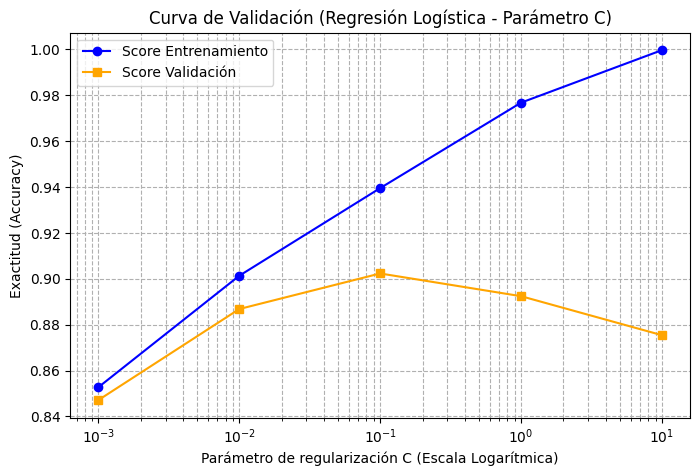

In [26]:
from sklearn.model_selection import validation_curve

#Para Regresion logistica
parametros = [0.001, 0.01, 0.1, 1, 10.0]

trian_scores_cv, val_scores_cv = validation_curve(
    Pipeline(
        [('Scaler', MinMaxScaler()), ('lr', LogisticRegression(max_iter=1000, n_jobs=-1))]
    ), 
    X_train_sub, y_train_sub, 
    param_name="lr__C", 
    param_range=parametros,
    cv = 3,
    scoring="accuracy",
    n_jobs=-1

)

train_mean_cv = np.mean(trian_scores_cv, axis=1)
val_mean_cv = np.mean(val_scores_cv, axis=1)


plt.figure(figsize=(8, 5))
plt.plot(parametros, train_mean_cv, label="Score Entrenamiento", marker='o', color='blue')
plt.plot(parametros, val_mean_cv, label="Score Validación", marker='s', color='orange')
plt.xscale('log')
plt.title("Curva de Validación (Regresión Logística - Parámetro C)")
plt.xlabel("Parámetro de regularización C (Escala Logarítmica)")
plt.ylabel("Exactitud (Accuracy)")
plt.legend()
plt.grid(True, which="both", ls="--")
plt.show()

- Costo Computacional: Se observa una clara disyuntiva entre la complejidad del algoritmo y sus tiempos de ejecución. Modelos lineales como la Regresión Logística entrenan de forma muy veloz, mientras que modelos basados en soporte vectorial (SVM) o ensambles grandes (Random Forest) incrementan notablemente el tiempo de cómputo en la fase de ajuste. En cuanto a la predicción, k-NN suele ser lento prediciendo con 60k datos (ya que calcula distancias contra todo el conjunto de entrenamiento), pero en este caso con el subconjunto se comporta de forma aceptable.

- Análisis de Curvas de Validación: La curva de validación sobre el parámetro C de la Regresión Logística muestra cómo valores muy pequeños de C (exceso de regularización) provocan un subajuste (baja exactitud tanto en train como en validación). Al incrementar C, el rendimiento mejora hasta estabilizarse, evitando caer en un sobreajuste severo gracias a la penalización óptima.

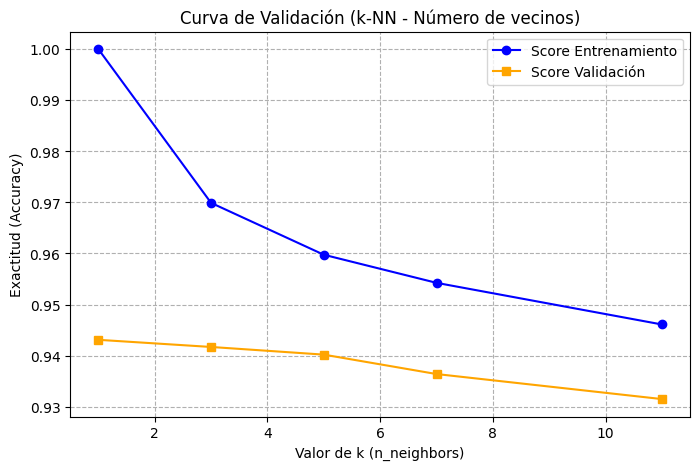

In [27]:
#Para KNN
parametros_KNN = [1, 3, 5, 7, 11]

train_score_knn, val_score_knn = validation_curve(
    Pipeline(
        [('Scaler', MinMaxScaler()), ('knn', KNeighborsClassifier())]
    ), 
    X_train_sub, y_train_sub,
    param_name="knn__n_neighbors",
    param_range=parametros_KNN,
    cv=3, 
    scoring="accuracy", 
    n_jobs=-1
)
plt.figure(figsize=(8, 5))
plt.plot(parametros_KNN, np.mean(train_score_knn, axis=1), label="Score Entrenamiento", marker='o', color='blue')
plt.plot(parametros_KNN, np.mean(val_score_knn, axis=1), label="Score Validación", marker='s', color='orange')
plt.title("Curva de Validación (k-NN - Número de vecinos)")
plt.xlabel("Valor de k (n_neighbors)")
plt.ylabel("Exactitud (Accuracy)")
plt.legend()
plt.grid(True, ls="--")
plt.show()


## 4. Actividad 4. Reducción de Dimensionalidad (PCA y t-SNE)



### 4a. Análisis de Componentes Principales (PCA)
*Varianza explicada acumulada, reconstrucción de imágenes con diferentes componentes y visualización 2D.*



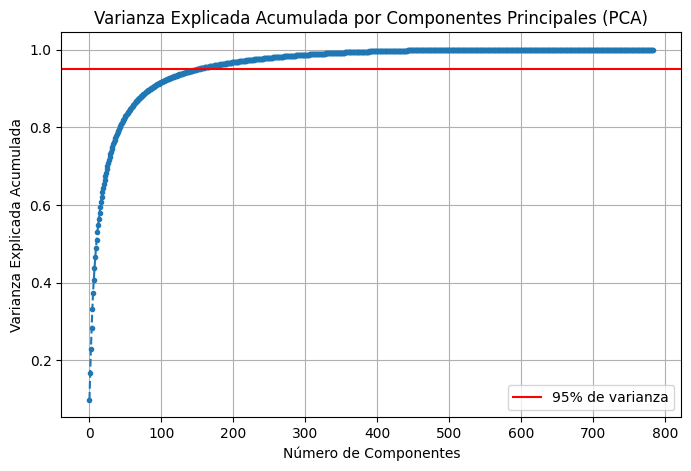

In [28]:
from sklearn.decomposition import PCA



#ajustamos pca con el conjutno de entrenamiento
pca_full = PCA(random_state=42)
pca_full.fit(X_train_sub)

#varianza acomulada
variaza_acumulada = np.cumsum(pca_full.explained_variance_ratio_)

#graficamos la varianza acumulada
plt.figure(figsize=(8, 5))
plt.plot(variaza_acumulada, marker='.', linestyle='--')
plt.axhline(y=0.95, color='r', linestyle='-', label='95% de varianza')
plt.title('Varianza Explicada Acumulada por Componentes Principales (PCA)')
plt.xlabel('Número de Componentes')
plt.ylabel('Varianza Explicada Acumulada')
plt.legend()
plt.grid(True)
plt.show()

In [30]:
#Buscamos los componentes para mantener la vatianza en 96%

n_componentes = np.argmax(variaza_acumulada >= 0.95) +1
print("Componentes necesarios para mantener el 95%  de la varinaza:", n_componentes)

Componentes necesarios para mantener el 95%  de la varinaza: 152


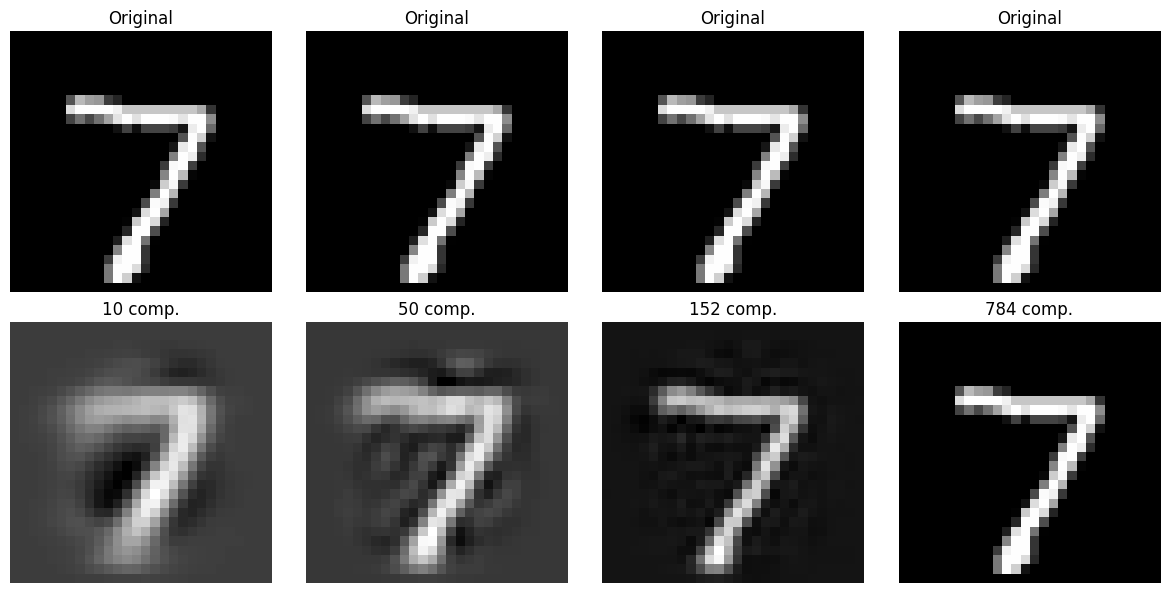

In [31]:
# 3. Probar la reconstrucción con diferentes números de componentes 
from sklearn.preprocessing import StandardScaler 

n_components_list = [10, 50, n_componentes, 784]
fig, axes = plt.subplots(2, len(n_components_list), figsize=(12, 6))

# Tomamos una imagen de prueba 
img_original = X_test[0].reshape(28, 28)

for i, n_comp in enumerate(n_components_list):
    # Aplicar PCA con n componentes
    pca_temp = PCA(n_components=n_comp, random_state=42)
    X_train_pca = pca_temp.fit_transform(X_train_sub)
    X_test_pca = pca_temp.transform(X_test[:1])
    
    # Reconstruir la imagen
    img_reconstruida = pca_temp.inverse_transform(X_test_pca).reshape(28, 28)
    
    # Mostrar original vs con caomponentes
    axes[0, i].imshow(img_original, cmap="gray")
    axes[0, i].set_title("Original")
    axes[0, i].axis("off")
    
    axes[1, i].imshow(img_reconstruida, cmap="gray")
    axes[1, i].set_title(f"{n_comp} comp.")
    axes[1, i].axis("off")

plt.tight_layout()
plt.show()

### 4b. Incrustación Estocástica de Vecinos Distribuida t (t-SNE)
*Proyección no lineal 2D sobre un subconjunto estratificado evaluando el parámetro de perplejidad ($perplexity \in \{5, 30, 50\}$).*

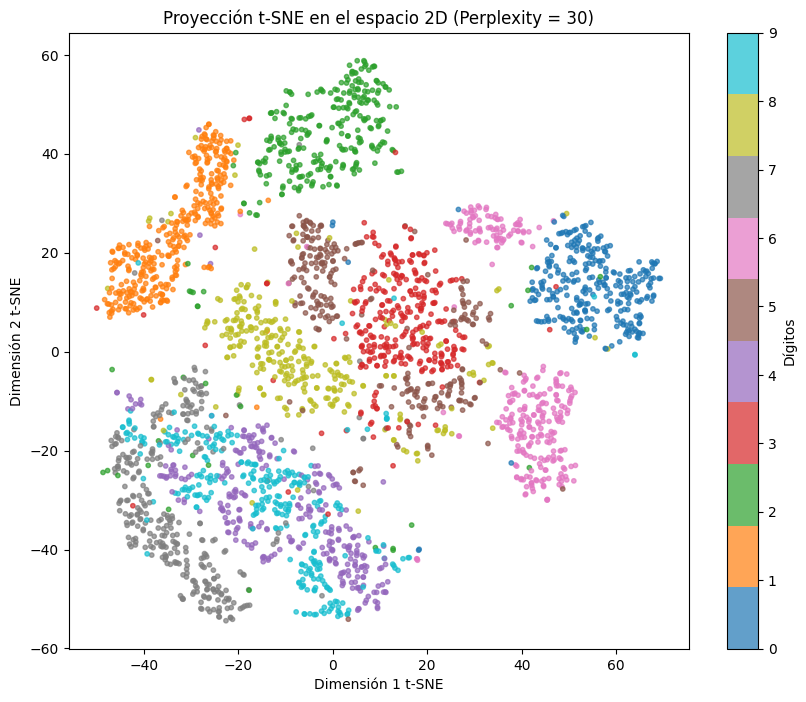

In [32]:
from sklearn.manifold import TSNE

X_tsne_set, _ , y_tsne_set, _ = train_test_split(
    X_train_sub, y_train_sub, train_size=3000, stratify=y_train_sub, random_state=42
)

tsne = TSNE(n_components=2, perplexity=30, random_state=42, max_iter=1000, n_jobs=-1)
X_embedded = tsne.fit_transform(X_tsne_set)

plt.figure(figsize=(10, 8))
scatter = plt.scatter(X_embedded[:, 0], X_embedded[:, 1], c=y_tsne_set, cmap='tab10', s=10, alpha=0.7)
plt.colorbar(scatter, ticks=range(10), label='Dígitos')
plt.title('Proyección t-SNE en el espacio 2D (Perplexity = 30)')
plt.xlabel('Dimensión 1 t-SNE')
plt.ylabel('Dimensión 2 t-SNE')
plt.show()

### 4c. Clasificación en el espacio reducido
*Evaluación de clasificadores en espacio transformado (Pipeline con PCA) vs. píxeles originales.*

In [33]:
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score

# Creamos un Pipeline que primero reduce dimensionalidad con PCA 
# y luego aplica un clasificador 
pipeline_pca_lr = Pipeline([
    ('scaler', MinMaxScaler()),
    ('pca', PCA(n_components=0.95, random_state=42)),
    ('clf', LogisticRegression(max_iter=1000, n_jobs=-1))
])

print("Entrenando clasificador con datos reducidos por PCA...")
inicio = time.time()
pipeline_pca_lr.fit(X_train_sub, y_train_sub)
t_entrenamiento_pca = time.time() - inicio

# Predicción y evaluación
preds_pca = pipeline_pca_lr.predict(X_test[:2000])
acc_pca = accuracy_score(y_test[:2000], preds_pca)

print(f"Exactitud con PCA (95% varianza): {acc_pca:.4f}")
print(f"Tiempo de entrenamiento con PCA: {t_entrenamiento_pca:.2f} segundos")

Entrenando clasificador con datos reducidos por PCA...


c:\Users\monts\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1457: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


Exactitud con PCA (95% varianza): 0.8800
Tiempo de entrenamiento con PCA: 1.66 segundos


---


## 5. Actividad 5. Métricas y Métodos de Evaluación



### 5a. Métricas multiclase en el conjunto de prueba
*Cálculo de Exactitud, Precisión, Sensibilidad, F1-score (macro y ponderado), Exactitud Balanceada, Kappa de Cohen y MCC.*



In [34]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    cohen_kappa_score,
    matthews_corrcoef,
    classification_report
)

# Predicciones de cada modelo para las 10,000 imágenes de prueba
predicciones_test = {}

for nombre, modelo in mejores_modelos.items():
    predicciones_test[nombre] = modelo.predict(X_test)

# Resumen de métricas por modelo
resultados_metricas = []

for nombre, y_pred in predicciones_test.items():
    resultados_metricas.append({
        "Modelo": nombre,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precisión macro": precision_score(
            y_test, y_pred, average="macro", zero_division=0
        ),
        "Sensibilidad macro": recall_score(
            y_test, y_pred, average="macro", zero_division=0
        ),
        "F1 macro": f1_score(
            y_test, y_pred, average="macro", zero_division=0
        ),
        "Precisión ponderada": precision_score(
            y_test, y_pred, average="weighted", zero_division=0
        ),
        "Sensibilidad ponderada": recall_score(
            y_test, y_pred, average="weighted", zero_division=0
        ),
        "F1 ponderado": f1_score(
            y_test, y_pred, average="weighted", zero_division=0
        ),
        "Exactitud balanceada": balanced_accuracy_score(y_test, y_pred),
        "Kappa de Cohen": cohen_kappa_score(y_test, y_pred),
        "MCC": matthews_corrcoef(y_test, y_pred)
    })

tabla_metricas = pd.DataFrame(resultados_metricas).set_index("Modelo")
display(tabla_metricas.round(4))

,Accuracy,Precisión macro,Sensibilidad macro,F1 macro,Precisión ponderada,Sensibilidad ponderada,F1 ponderado,Exactitud balanceada,Kappa de Cohen,MCC
Modelo,,,,,,,,,,
k-NN,0.9481,0.9494,0.9475,0.9480,0.9489,0.9481,0.9480,0.9475,0.9423,0.9424
Regresión Logística,0.9110,0.9099,0.9097,0.9096,0.9107,0.9110,0.9106,0.9097,0.9011,0.9011
SVM (RBF),0.9426,0.9421,0.9418,0.9418,0.9425,0.9426,0.9424,0.9418,0.9362,0.9362
Árbol de Decisión,0.8238,0.8215,0.8216,0.8213,0.8233,0.8238,0.8233,0.8216,0.8041,0.8042
Random Forest,0.9518,0.9517,0.9513,0.9514,0.9519,0.9518,0.9518,0.9513,0.9464,0.9464


In [35]:
for nombre, y_pred in predicciones_test.items():
    print(f"\nReporte por dígito: {nombre}")
    print(classification_report(
        y_test,
        y_pred,
        labels=np.arange(10),
        target_names=[str(digito) for digito in range(10)],
        digits=4,
        zero_division=0
    ))


Reporte por dígito: k-NN
              precision    recall  f1-score   support

           0     0.9530    0.9929    0.9725       980
           1     0.9277    0.9947    0.9600      1135
           2     0.9824    0.9215    0.9510      1032
           3     0.9305    0.9416    0.9360      1010
           4     0.9684    0.9348    0.9513       982
           5     0.9489    0.9361    0.9424       892
           6     0.9701    0.9812    0.9756       958
           7     0.9322    0.9358    0.9340      1028
           8     0.9732    0.8943    0.9320       974
           9     0.9074    0.9425    0.9246      1009

    accuracy                         0.9481     10000
   macro avg     0.9494    0.9475    0.9480     10000
weighted avg     0.9489    0.9481    0.9480     10000


Reporte por dígito: Regresión Logística
              precision    recall  f1-score   support

           0     0.9338    0.9786    0.9557       980
           1     0.9527    0.9753    0.9639      1135
           

In [36]:
for nombre, y_pred in predicciones_test.items():
    print(nombre, round(accuracy_score(y_test, y_pred), 4))

k-NN 0.9481
Regresión Logística 0.911
SVM (RBF) 0.9426
Árbol de Decisión 0.8238
Random Forest 0.9518


### 5b. Matriz de confusión y análisis de errores
*Matriz de confusión absoluta y normalizada, contraste contra la hipótesis del EDA y análisis de los 20 errores con mayor nivel de confianza.*



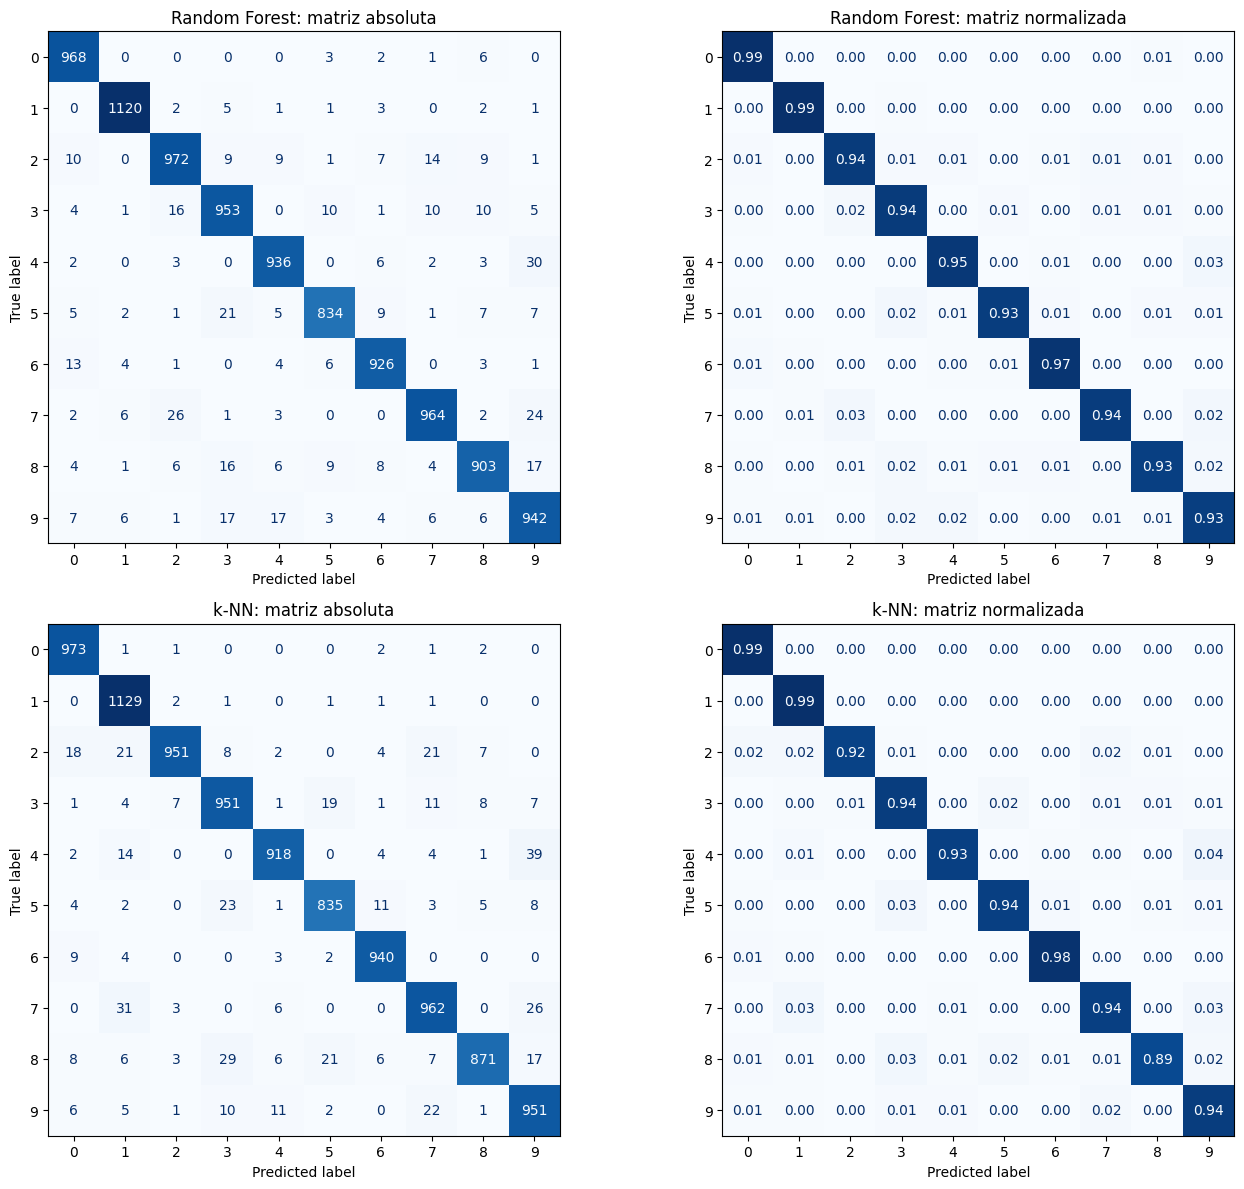

In [37]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

modelos_top = ["Random Forest", "k-NN"]
matrices_confusion = {}

fig, axes = plt.subplots(2, 2, figsize=(14, 12))

for fila, nombre in enumerate(modelos_top):
    y_pred = predicciones_test[nombre]

    matriz = confusion_matrix(
        y_test, y_pred, labels=np.arange(10)
    )
    matriz_norm = confusion_matrix(
        y_test, y_pred, labels=np.arange(10), normalize="true"
    )

    matrices_confusion[nombre] = (matriz, matriz_norm)

    ConfusionMatrixDisplay(
        confusion_matrix=matriz,
        display_labels=np.arange(10)
    ).plot(
        ax=axes[fila, 0],
        cmap="Blues",
        values_format="d",
        colorbar=False
    )
    axes[fila, 0].set_title(f"{nombre}: matriz absoluta")

    ConfusionMatrixDisplay(
        confusion_matrix=matriz_norm,
        display_labels=np.arange(10)
    ).plot(
        ax=axes[fila, 1],
        cmap="Blues",
        values_format=".2f",
        colorbar=False
    )
    axes[fila, 1].set_title(f"{nombre}: matriz normalizada")

plt.tight_layout()
plt.show()

In [38]:
# Tres parejas de promedios más cercanas según el EDA
pares_eda = sorted(
    (distancias[i, j], i, j)
    for i in range(10)
    for j in range(i + 1, 10)
)[:3]

print("Tres parejas más cercanas según el EDA:")
for distancia, digito_a, digito_b in pares_eda:
    print(f"{digito_a} y {digito_b}: distancia {distancia:.2f}")

# Parejas que más se confunden según las matrices normalizadas
for nombre in modelos_top:
    matriz, matriz_norm = matrices_confusion[nombre]

    pares_confundidos = []
    for i in range(10):
        for j in range(i + 1, 10):
            tasa = (matriz_norm[i, j] + matriz_norm[j, i]) / 2
            errores = matriz[i, j] + matriz[j, i]
            pares_confundidos.append((tasa, errores, i, j))

    pares_confundidos.sort(reverse=True)

    print(f"\nTres parejas más confundidas por {nombre}:")
    for tasa, errores, digito_a, digito_b in pares_confundidos[:3]:
        print(
            f"{digito_a} y {digito_b}: "
            f"tasa promedio={tasa:.4f}, errores en ambos sentidos={errores}"
        )

Tres parejas más cercanas según el EDA:
4 y 9: distancia 635.08
7 y 9: distancia 767.36
5 y 8: distancia 791.24

Tres parejas más confundidas por Random Forest:
4 y 9: tasa promedio=0.0237, errores en ambos sentidos=47
2 y 7: tasa promedio=0.0194, errores en ambos sentidos=40
3 y 5: tasa promedio=0.0167, errores en ambos sentidos=31

Tres parejas más confundidas por k-NN:
4 y 9: tasa promedio=0.0253, errores en ambos sentidos=50
7 y 9: tasa promedio=0.0235, errores en ambos sentidos=48
3 y 5: tasa promedio=0.0223, errores en ambos sentidos=42


In [39]:
# Tomamos el mejor modelo según la tabla: Random Forest
modelo_rf = mejores_modelos["Random Forest"]
y_pred_rf = predicciones_test["Random Forest"]

# Probabilidades asignadas por Random Forest a cada clase
probabilidades_rf = modelo_rf.predict_proba(X_test)

# Confianza de la clase que el modelo predijo
confianza_predicha = probabilidades_rf.max(axis=1)

# Índices de las imágenes mal clasificadas
indices_error = np.where(y_pred_rf != y_test)[0]

# Elegimos los 20 errores con mayor confianza
orden = np.argsort(confianza_predicha[indices_error])[::-1]
indices_20 = indices_error[orden[:20]]

# Tabla con el resultado
tabla_errores = pd.DataFrame({
    "Índice en prueba": indices_20,
    "Dígito real": y_test[indices_20],
    "Predicción": y_pred_rf[indices_20],
    "Confianza de la predicción": confianza_predicha[indices_20]
})

display(tabla_errores.round(4))

,Índice en prueba,Dígito real,Predicción,Confianza de la predicción
0,1681,3,7,0.91
1,9009,7,2,0.83
2,4224,9,7,0.83
3,3520,6,4,0.78
4,7121,8,9,0.74
5,4601,8,4,0.74
6,2130,4,9,0.72
7,381,3,7,0.69
8,8094,2,8,0.69
9,321,2,7,0.67


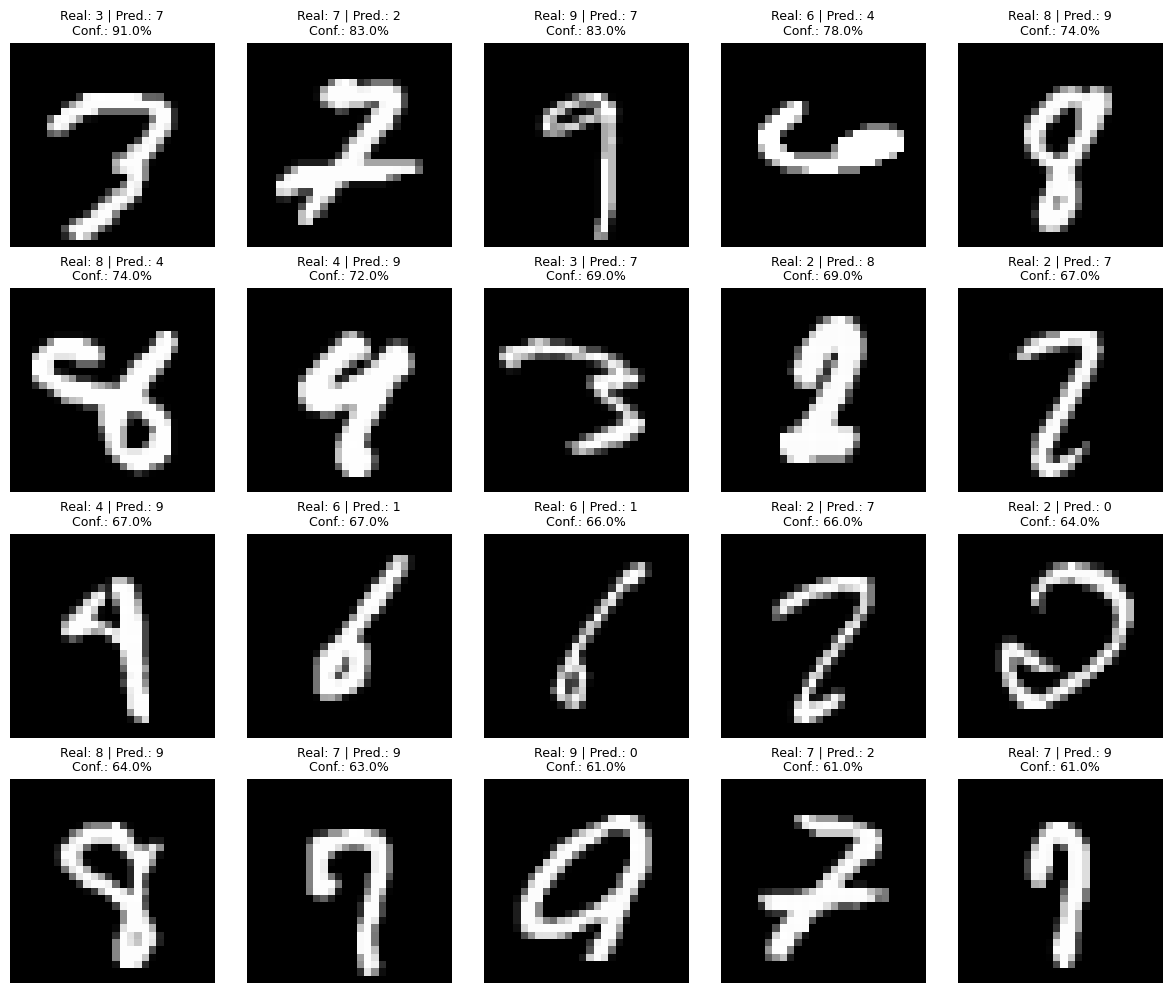

In [40]:
fig, axes = plt.subplots(4, 5, figsize=(12, 10))

for ax, indice in zip(axes.flat, indices_20):
    ax.imshow(X_test[indice].reshape(28, 28), cmap="gray")
    ax.set_title(
        f"Real: {y_test[indice]} | Pred.: {y_pred_rf[indice]}\n"
        f"Conf.: {confianza_predicha[indice]:.1%}",
        fontsize=9
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

### 5c. Curvas ROC, PR y calibración de probabilidades
*Evaluación de umbrales mediante curvas ROC / PR uno-contra-todos, Log Loss y diagramas de calibración.*

In [41]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    roc_curve,
    precision_recall_curve
)

clases = np.arange(10)
y_test_binario = label_binarize(y_test, classes=clases)

puntajes_modelos = {}
resultados_curvas = []

# Obtener puntajes continuos de cada modelo.
# SVM usa decision_function; los demás usan predict_proba.
for nombre, modelo in mejores_modelos.items():
    if hasattr(modelo, "predict_proba"):
        puntajes = modelo.predict_proba(X_test)
        tipo_puntaje = "Probabilidades"
    else:
        puntajes = modelo.decision_function(X_test)
        tipo_puntaje = "Función de decisión"

    puntajes_modelos[nombre] = puntajes

    resultados_curvas.append({
        "Modelo": nombre,
        "Tipo de puntaje": tipo_puntaje,
        "AUC ROC macro": roc_auc_score(
            y_test_binario, puntajes, average="macro"
        ),
        "Average Precision macro": average_precision_score(
            y_test_binario, puntajes, average="macro"
        )
    })

tabla_curvas = pd.DataFrame(resultados_curvas).set_index("Modelo")
display(tabla_curvas.round(4))

,Tipo de puntaje,AUC ROC macro,Average Precision macro
Modelo,,,
k-NN,Probabilidades,0.9875,0.9625
Regresión Logística,Probabilidades,0.9928,0.9635
SVM (RBF),Función de decisión,0.9893,0.9549
Árbol de Decisión,Probabilidades,0.9108,0.7406
Random Forest,Probabilidades,0.9975,0.9844


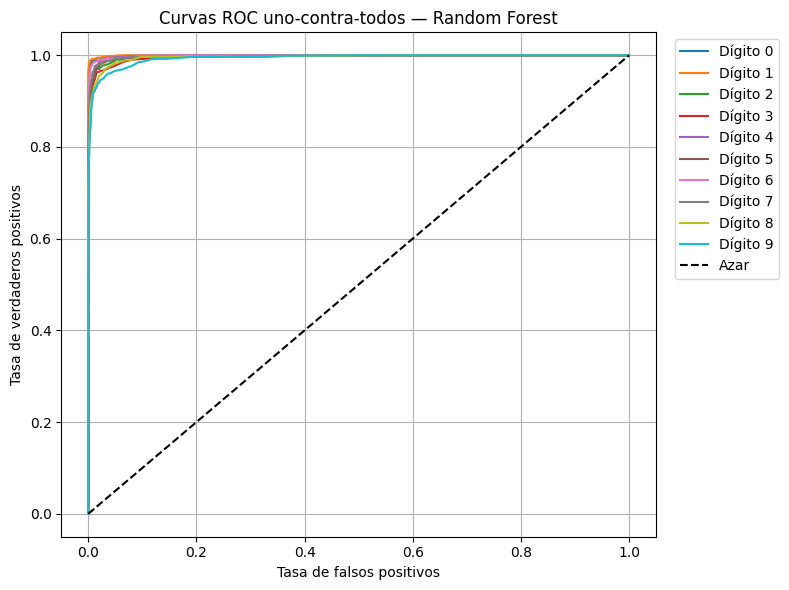

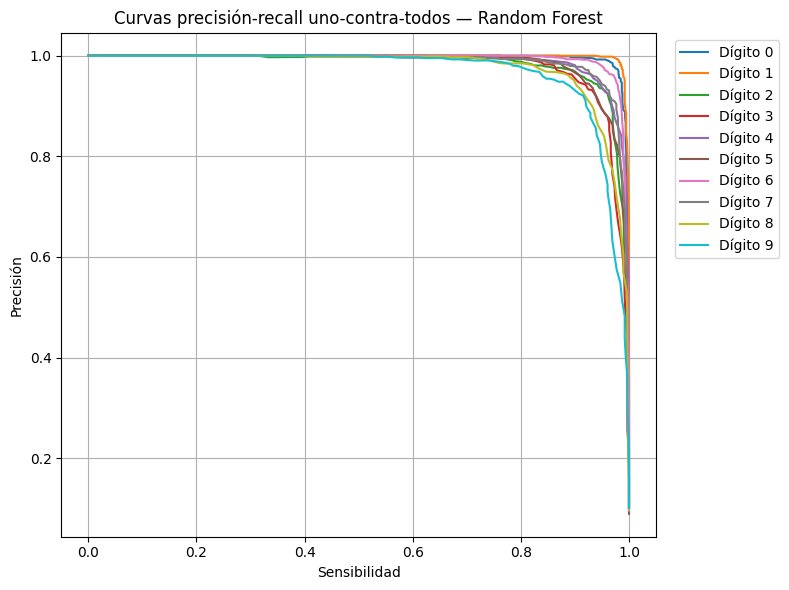

In [42]:
puntajes_rf = puntajes_modelos["Random Forest"]

# Curvas ROC uno-contra-todos
plt.figure(figsize=(8, 6))

for indice, digito in enumerate(clases):
    fpr, tpr, _ = roc_curve(
        y_test_binario[:, indice],
        puntajes_rf[:, indice]
    )
    plt.plot(fpr, tpr, label=f"Dígito {digito}")

plt.plot([0, 1], [0, 1], "k--", label="Azar")
plt.xlabel("Tasa de falsos positivos")
plt.ylabel("Tasa de verdaderos positivos")
plt.title("Curvas ROC uno-contra-todos — Random Forest")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid()
plt.tight_layout()
plt.show()


# Curvas precisión-recall uno-contra-todos
plt.figure(figsize=(8, 6))

for indice, digito in enumerate(clases):
    precision, sensibilidad, _ = precision_recall_curve(
        y_test_binario[:, indice],
        puntajes_rf[:, indice]
    )
    plt.plot(sensibilidad, precision, label=f"Dígito {digito}")

plt.xlabel("Sensibilidad")
plt.ylabel("Precisión")
plt.title("Curvas precisión-recall uno-contra-todos — Random Forest")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid()
plt.tight_layout()
plt.show()

SVM (RBF): se omite de Log Loss y calibración porque no entrega probabilidades.


,Modelo,Log Loss
1,Regresión Logística,0.303454
3,Random Forest,0.384045
0,k-NN,0.862063
2,Árbol de Decisión,3.999335


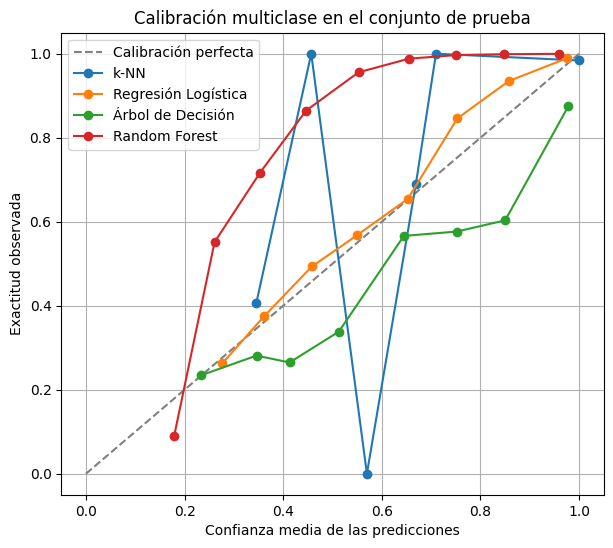

In [43]:
from sklearn.metrics import log_loss
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

resultados_calibracion = []
curvas_calibracion = {}

for nombre, modelo in mejores_modelos.items():
    # SVM no tiene predict_proba si se entrenó con probability=False
    if not hasattr(modelo, "predict_proba"):
        print(f"{nombre}: se omite de Log Loss y calibración porque no entrega probabilidades.")
        continue

    probabilidades = modelo.predict_proba(X_test)
    predicciones = np.argmax(probabilidades, axis=1)
    confianza = np.max(probabilidades, axis=1)
    acierto = (predicciones == y_test).astype(int)

    perdida = log_loss(y_test, probabilidades, labels=modelo.classes_)

    # Agrupamos predicciones por nivel de confianza para la curva multiclase
    limites = np.linspace(0, 1, 11)
    confianza_media = []
    exactitud_por_grupo = []

    for i in range(len(limites) - 1):
        mascara = (confianza >= limites[i]) & (confianza < limites[i + 1])

        # Incluir confianza exactamente igual a 1 en el último grupo
        if i == len(limites) - 2:
            mascara |= (confianza == 1)

        if mascara.any():
            confianza_media.append(confianza[mascara].mean())
            exactitud_por_grupo.append(acierto[mascara].mean())

    curvas_calibracion[nombre] = (confianza_media, exactitud_por_grupo)
    resultados_calibracion.append({
        "Modelo": nombre,
        "Log Loss": perdida
    })

tabla_logloss = pd.DataFrame(resultados_calibracion).sort_values("Log Loss")
display(tabla_logloss)

plt.figure(figsize=(7, 6))
plt.plot([0, 1], [0, 1], "--", color="gray", label="Calibración perfecta")

for nombre, (conf_media, acc_grupo) in curvas_calibracion.items():
    plt.plot(conf_media, acc_grupo, marker="o", label=nombre)

plt.xlabel("Confianza media de las predicciones")
plt.ylabel("Exactitud observada")
plt.title("Calibración multiclase en el conjunto de prueba")
plt.legend()
plt.grid(True)
plt.show()


---

## 6. Actividad 6. Pruebas Estadísticas de Significancia



### 6a. Prueba de McNemar
*Evaluación de la tasa de error entre los dos mejores clasificadores sobre el conjunto de prueba único (Tabla de contingencia $2 \times 2$).*



In [17]:
%pip install statsmodels

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.1/12.1 MB 4.9 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [statsmodels] [statsmodels]
Note: you may need to restart the kernel to use updated packages.


In [18]:
import numpy as np
import pandas as pd
from statsmodels.stats.contingency_tables import mcnemar

# Usar las predicciones de la evaluación anterior para conservar
# los mismos modelos y el mismo conjunto de prueba.
if (
    "predicciones_test" in globals()
    and isinstance(predicciones_test, dict)
    and "Random Forest" in predicciones_test
    and "k-NN" in predicciones_test
):
    pred_rf = np.asarray(predicciones_test["Random Forest"])
    pred_knn = np.asarray(predicciones_test["k-NN"])
else:
    pred_rf = mejores_modelos["Random Forest"].predict(X_test)
    pred_knn = mejores_modelos["k-NN"].predict(X_test)

y_real = np.asarray(y_test)

# Comprobar que las tres secuencias corresponden a las mismas imágenes
assert len(y_real) == len(pred_rf) == len(pred_knn)

rf_acierta = (pred_rf == y_real)
knn_acierta = (pred_knn == y_real)

# Tabla: filas = Random Forest; columnas = k-NN
ambos_aciertan = np.sum(rf_acierta & knn_acierta)
rf_acierta_knn_falla = np.sum(rf_acierta & ~knn_acierta)
rf_falla_knn_acierta = np.sum(~rf_acierta & knn_acierta)
ambos_fallan = np.sum(~rf_acierta & ~knn_acierta)

tabla_contingencia = np.array([
    [ambos_aciertan,       rf_acierta_knn_falla],
    [rf_falla_knn_acierta, ambos_fallan]
])

display(pd.DataFrame(
    tabla_contingencia,
    index=["RF acierta", "RF falla"],
    columns=["k-NN acierta", "k-NN falla"]
))

# Si hay menos de 25 desacuerdos, se usa la prueba exacta
desacuerdos = rf_acierta_knn_falla + rf_falla_knn_acierta
usar_exacto = desacuerdos < 25

resultado = mcnemar(
    tabla_contingencia,
    exact=usar_exacto,
    correction=not usar_exacto
)

print(f"Desacuerdos entre modelos: {desacuerdos}")
print(f"Versión utilizada: {'exacta' if usar_exacto else 'chi-cuadrada con corrección'}")
print(f"Estadístico de McNemar: {resultado.statistic}")
print(f"Valor p: {resultado.pvalue:.6f}")

NameError: name 'mejores_modelos' is not defined

### 6b. Prueba de rangos con signo de Wilcoxon
*Análisis de diferencias pareadas entre pliegues de validación para los dos mejores modelos.*



In [47]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from scipy.stats import wilcoxon

# Diez pliegues estratificados; usamos solo datos de entrenamiento
cv_10 = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

modelo_rf = mejores_modelos["Random Forest"]
modelo_knn = mejores_modelos["k-NN"]

# n_jobs=1 evita paralelismo anidado; los modelos pueden usar sus propios recursos
puntajes_rf = cross_val_score(
    modelo_rf, X_train_sub, y_train_sub,
    cv=cv_10, scoring="accuracy", n_jobs=1
)

puntajes_knn = cross_val_score(
    modelo_knn, X_train_sub, y_train_sub,
    cv=cv_10, scoring="accuracy", n_jobs=1
)

print("Accuracy por pliegue — Random Forest:")
print(np.round(puntajes_rf, 4))

print("\nAccuracy por pliegue — k-NN:")
print(np.round(puntajes_knn, 4))

resultado_wilcoxon = wilcoxon(
    puntajes_rf,
    puntajes_knn,
    alternative="two-sided"
)

print(f"\nEstadístico de Wilcoxon: {resultado_wilcoxon.statistic:.4f}")
print(f"Valor p: {resultado_wilcoxon.pvalue:.6f}")
print(f"Media RF:  {puntajes_rf.mean():.4f}")
print(f"Media k-NN: {puntajes_knn.mean():.4f}")

Accuracy por pliegue — Random Forest:
[0.952 0.96  0.94  0.953 0.938 0.951 0.937 0.945 0.948 0.949]

Accuracy por pliegue — k-NN:
[0.953 0.95  0.949 0.956 0.956 0.956 0.941 0.948 0.946 0.948]

Estadístico de Wilcoxon: 13.5000
Valor p: 0.169922
Media RF:  0.9473
Media k-NN: 0.9503


### 6c. Prueba de Friedman y análisis Post-Hoc
*Comparación global entre todos los modelos y prueba Post-Hoc de Nemenyi / Wilcoxon corregido.*



In [48]:
from sklearn.model_selection import cross_val_score
from scipy.stats import friedmanchisquare, wilcoxon
from statsmodels.stats.multitest import multipletests
import pandas as pd
import numpy as np

# Usa el mismo conjunto reducido y la misma partición de 10 pliegues
puntajes_todos = {}

for nombre, modelo in mejores_modelos.items():
    puntajes_todos[nombre] = cross_val_score(
        modelo,
        X_train_sub,
        y_train_sub,
        cv=cv_10,
        scoring="accuracy",
        n_jobs=1
    )

tabla_puntajes = pd.DataFrame(puntajes_todos)
display(tabla_puntajes.round(4))

# Prueba de Friedman para comparar los cinco modelos
resultado_friedman = friedmanchisquare(
    *[puntajes_todos[nombre] for nombre in puntajes_todos]
)

print(f"Estadístico de Friedman: {resultado_friedman.statistic:.4f}")
print(f"Valor p: {resultado_friedman.pvalue:.6f}")

c:\Users\monts\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1457: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
c:\Users\monts\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1457: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
c:\Users\monts\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1457: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
c:\Users\monts\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1457: FutureWarning: 'n

,k-NN,Regresión Logística,SVM (RBF),Árbol de Decisión,Random Forest
0,0.953,0.905,0.930,0.800,0.952
1,0.950,0.917,0.942,0.804,0.960
2,0.949,0.898,0.926,0.799,0.940
3,0.956,0.906,0.939,0.808,0.953
4,0.956,0.902,0.931,0.818,0.938
5,0.956,0.922,0.944,0.826,0.951
6,0.941,0.889,0.928,0.775,0.937
7,0.948,0.908,0.931,0.810,0.945
8,0.946,0.905,0.933,0.799,0.948
9,0.948,0.909,0.927,0.796,0.949


Estadístico de Friedman: 38.3200
Valor p: 0.000000


In [49]:
%pip install scikit-posthocs

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Valores p de Nemenyi:


,k-NN,Regresión Logística,SVM (RBF),Árbol de Decisión,Random Forest
k-NN,1.0000,0.0013,0.1141,0.0000,0.9800
Regresión Logística,0.0013,1.0000,0.6184,0.6184,0.0101
SVM (RBF),0.1141,0.6184,1.0000,0.0377,0.3513
Árbol de Decisión,0.0000,0.6184,0.0377,1.0000,0.0000
Random Forest,0.9800,0.0101,0.3513,0.0000,1.0000


Rango promedio por modelo (menor es mejor):


k-NN                   1.3
Random Forest          1.7
SVM (RBF)              3.0
Regresión Logística    4.0
Árbol de Decisión      5.0
dtype: float64

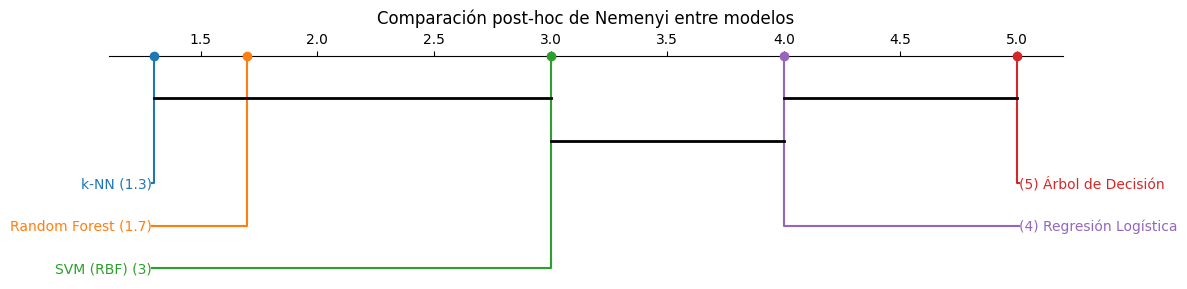

In [50]:
import scikit_posthocs as sp
import matplotlib.pyplot as plt
import pandas as pd

# Post-hoc de Nemenyi: filas = pliegues, columnas = modelos
matriz_nemenyi = sp.posthoc_nemenyi_friedman(tabla_puntajes)

# Asegurar que las etiquetas de los modelos aparezcan en la tabla
matriz_nemenyi.index = tabla_puntajes.columns
matriz_nemenyi.columns = tabla_puntajes.columns

print("Valores p de Nemenyi:")
display(matriz_nemenyi.round(4))

# En accuracy, un rango 1 corresponde al mejor modelo de cada pliegue
rangos_promedio = tabla_puntajes.rank(
    axis=1,
    ascending=False
).mean()

print("Rango promedio por modelo (menor es mejor):")
display(rangos_promedio.sort_values().round(3))

# Diagrama de diferencia crítica
plt.figure(figsize=(12, 3))
sp.critical_difference_diagram(
    ranks=rangos_promedio,
    sig_matrix=matriz_nemenyi,
    alpha=0.05
)
plt.title("Comparación post-hoc de Nemenyi entre modelos")
plt.tight_layout()
plt.show()

### 6d. Discusión metodológica y conclusión
*Análisis de limitaciones de las pruebas sobre K-Fold y fundamentación de las limitaciones de los modelos clásicos frente a redes neuronales convolucionales.*

En la validación cruzada de 10 pliegues, k-NN obtuvo el mejor rango promedio (1.3), seguido de Random Forest (1.7). Friedman detectó diferencias globales entre los cinco clasificadores (\(p<0.001\)); el post-hoc de Nemenyi mostró que k-NN y Random Forest tuvieron un desempeño similar entre sí, mientras que el árbol de decisión ocupó el último lugar. En las comparaciones de los dos mejores modelos, Wilcoxon (\(p=0.1699\)) y McNemar (\(p\approx0.09\)) no encontraron evidencia suficiente para afirmar que sus resultados fueran distintos.
Estos resultados deben interpretarse con cautela. Los pliegues de validación cruzada comparten datos de entrenamiento, por lo que sus puntajes no son totalmente independientes; además, estas pruebas se diseñaron principalmente para comparar modelos en varios conjuntos de datos. En MNIST, los clasificadores clásicos trabajan principalmente con características de píxeles y no modelan explícitamente la estructura espacial de la imagen. Una CNN puede aprender patrones locales y jerárquicos, como trazos y partes de dígitos, aunque su ventaja debe comprobarse experimentalmente y depende de su arquitectura y ajuste.

NameError: name 'matplotlib' is not defined